Ryan Hughes Assignment 2 CNET 5051, Fall 2026
---

**Overall Instructions:** Due by Friday, Oct. 30th, 11:00pm EST. Please submit a .pdf of your answers
via Canvas, including a url to your .ipynb notebook in a public GitHub repository. Use the provided LATEX
template for your submission. Please name your Canvas submission as Lastname.pdf, (e.g. Trujillo.pdf). If
you need help with LATEX or GitHub, please visit during office hours or post questions to the Canvas. Include
your code in a (well-documented, commented, clear) assignment02.ipynb file. Scores for the code-based
questions below will be based on your written responses and code.

**Problem 1 (20 points)**
In this question we will work with degree-controlled random graph null models.

(a) The Configuration Model (5 points).
First, implement the configuration model in Python. Your function should take a list of integers
as a degree sequence, and return a graph where each vertex has the assigned degree. You graph
may contain duplicate edges and self-loops.

(b) The Chung Lu Model (5 points).
Next, implement the Chung Lu random graph model. Remember that this model creates an
edge between nodes i and j with independent probabilities defined by vertex degree and the total
number of edges in the graph:
pij = kikj
2m ,
where 2m := ∑︁
i ki.
Your implementation should take a list of integers as a degree sequence, and return a simple graph
with approximately the desired degree sequence.

(c) Model Differences (5 points).
For the degree sequence degrees=[8,5,5,4,3,2,2,2,1,1,1,1,1,1,1], generate a thousand ran-
dom graphs using the Configuration Model and the Chung Lu model, then:

(i) Plot the average adjacency matrix for each model. This should be a heatmap of:
⟨A⟩ = 1
N
N∑︂
i=1
Ai
where N is the number of generated random graphs, and Ai is the adjacency matrix of the
ith graph. (Hint: matplotlib’s imshow is useful for displaying matrix data.)

(ii) Choose two graph metrics: one that should be approximately the same across graphs gen-
erated by both models, and one that should diverge significantly between the two models.
For each metric, make a plot (histogram, kernel-density estimate, or cumulative distribution
function) showing the distribution of the metric across all generated graphs from each model.
Note: For this stage you may remove self-loops and duplicate edges from your configuration
model graphs if it helps make a direct comparison to Chung Lu graphs.

(d) Discussion (5 points).
Discuss the above results briefly. Why do the models produce similar results under some metrics
and different results under others?


/tmp/ipykernel_68434/192243778.py:167: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  configs += (nx.adjacency_matrix(configuration_model_from_degree_sequence(degrees)))
/tmp/ipykernel_68434/192243778.py:168: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  chung_lus += (nx.adjacency_matrix(chung_lu_model_from_degree_sequence(degrees)))


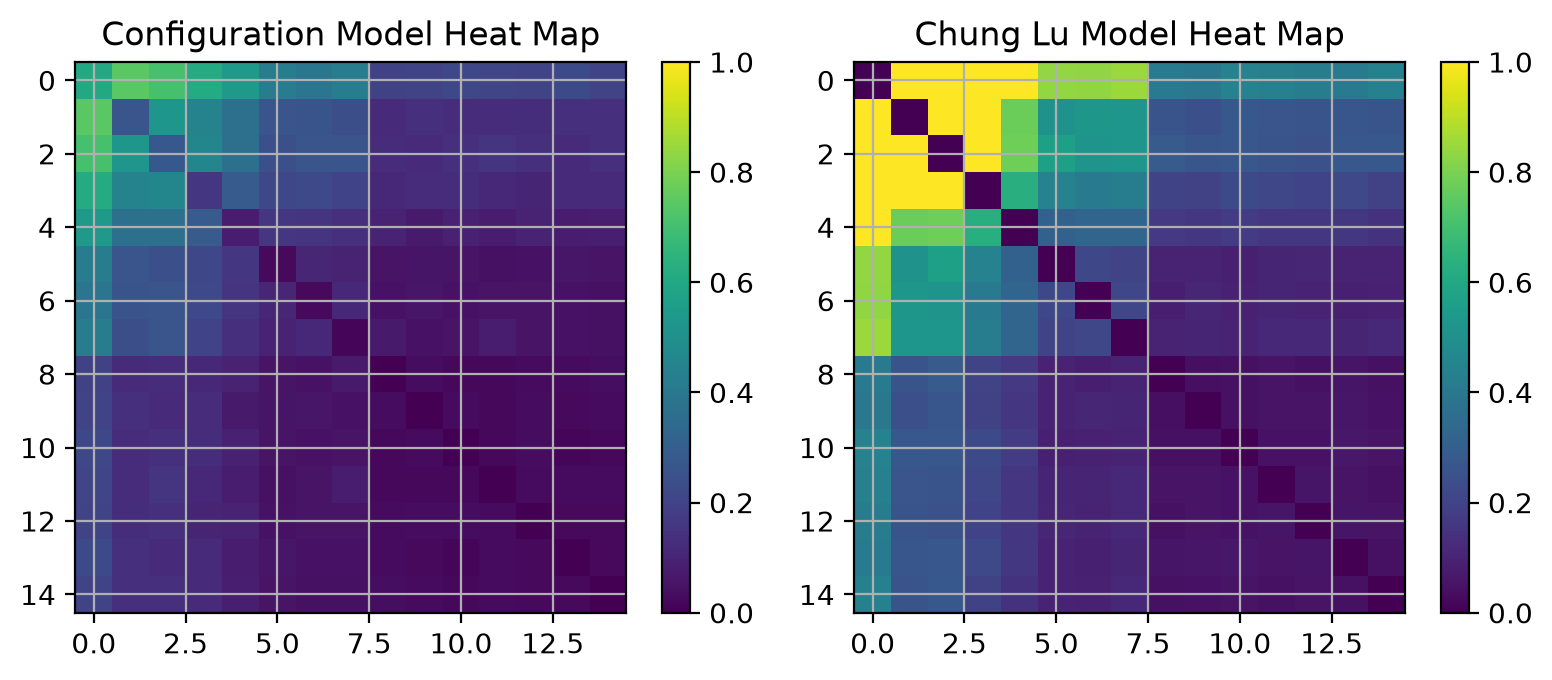

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from itertools import combinations
import logging

def configuration_model_from_degree_sequence(degree_sequence, return_simple=True):
    """
    Generate a random graph using the configuration model from a given degree sequence
    without using the NetworkX built-in function.

    The configuration model generates a random graph that preserves the degree 
    sequence of nodes by assigning "stubs" or "half-edges" to each node and 
    randomly pairing these stubs to form edges. This process can result in 
    graphs with self-loops and parallel edges, which can be removed if needed.

    Parameters
    ----------
    degree_sequence : list of int
        A list representing the degree of each node in the graph. The sum of 
        the degrees in this sequence must be even for the configuration model 
        to create a valid graph.

    Returns
    -------
    G : networkx.MultiGraph
        A multigraph generated from the given degree sequence. The graph may 
        contain self-loops and parallel edges, which are allowed in the 
        configuration model.

    Notes
    -----
    - This method works by assigning "stubs" or "half-edges" to nodes based on 
      their degree and then randomly pairing them to form edges. The resulting 
      graph can have self-loops and parallel edges.
    - Self-loops and parallel edges can be removed post-generation if a simple 
      graph is required using NetworkX's `nx.Graph(G)`.
    - The degree sequence must have an even sum for a valid graph construction. 
      If the sum of the degrees is odd, no graph can be constructed.

    Time Complexity
    ---------------
    The time complexity is O(E), where E is the number of edges in the graph.

    Example
    -------
    >>> degree_sequence = [3, 3, 2, 2, 1, 1]
    >>> G = configuration_model_from_degree_sequence(degree_sequence)
    >>> nx.is_graphical(degree_sequence)
    True
    """

    # Check if the degree sequence is valid (sum of degrees must be even)
    if sum(degree_sequence) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")

    # Create stubs list: node i appears degree_sequence[i] times
    stubs = []
    for node, degree in enumerate(degree_sequence):
        stubs.extend([node] * degree)

    # Shuffle stubs to randomize the pairing process
    np.random.shuffle(stubs)

    # Initialize an empty multigraph
    G = nx.MultiGraph()

    # Add nodes to the graph
    G.add_nodes_from(range(len(degree_sequence)))

    # Pair stubs to create edges
    while stubs:
        u = stubs.pop()
        v = stubs.pop()

        # Add the edge to the graph
        G.add_edge(u, v)

    if return_simple:
        # Convert the multigraph to a simple graph (remove parallel edges and self-loops)
        G_simple = nx.Graph(G)  # This removes parallel edges and self-loops by default

        return G_simple

    else:
        return G


def chung_lu_model_from_degree_sequence(degree_sequence, return_simple=True):
    """
    Generate a random graph using the configuration model from a given degree sequence
    without using the NetworkX built-in function.

    The configuration model generates a random graph that preserves the degree 
    sequence of nodes by assigning "stubs" or "half-edges" to each node and 
    randomly pairing these stubs to form edges. This process can result in 
    graphs with self-loops and parallel edges, which can be removed if needed.

    Parameters
    ----------
    degree_sequence : list of int
        A list representing the degree of each node in the graph. The sum of 
        the degrees in this sequence must be even for the configuration model 
        to create a valid graph.

    Returns
    -------
    G : networkx.MultiGraph
        A multigraph generated from the given degree sequence. The graph may 
        contain self-loops and parallel edges, which are allowed in the 
        configuration model.

    Notes
    -----
    - This method works by assigning "stubs" or "half-edges" to nodes based on 
      their degree and then randomly pairing them to form edges. The resulting 
      graph can have self-loops and parallel edges.
    - Self-loops and parallel edges can be removed post-generation if a simple 
      graph is required using NetworkX's `nx.Graph(G)`.
    - The degree sequence must have an even sum for a valid graph construction. 
      If the sum of the degrees is odd, no graph can be constructed.

    Time Complexity
    ---------------
    The time complexity is O(E), where E is the number of edges in the graph.

    Example
    -------
    >>> degree_sequence = [3, 3, 2, 2, 1, 1]
    >>> G = configuration_model_from_degree_sequence(degree_sequence)
    >>> nx.is_graphical(degree_sequence)
    True
    """

    G = nx.Graph()
    # Check if the degree sequence is valid (sum of degrees must be even)
    if sum(degree_sequence) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")

    #First calculate the total number of edges in the graph by taking the sum of the degree sequence
    total_edges = sum(degree_sequence) // 2
    degree_dict = {i: degree_sequence[i] for i in range(len(degree_sequence))}
    #print("The Original Degree Sequence is:", degree_dict)
    for a, b in combinations(degree_dict, 2):#For all "n choose 2" pairs of nodes...
        #Get their respective degrees ki, kj...
        ki = degree_dict[a]
        kj = degree_dict[b]
        #And, Calculate pij from the Chung-Lu model formula: pij = (ki * kj) / (total_edges)
        pij = (ki * kj) / (total_edges)
        if np.random.rand() < pij:#If a random number is less than pij, add an edge between the two nodes
            G.add_edge(a, b)
        else:#Add the nodes but without the edge
            G.add_node(a)
            G.add_node(b)
    #print("Chung Lu Approximation is:", dict(G.degree()))
    return G

#(b) Testing
degrees=[8,5,5,4,3,2,2,2,1,1,1,1,1,1,1]
chung_lu_graph = chung_lu_model_from_degree_sequence(degrees)

#(c) Testing
chung_lus = 0
configs = 0
for i in range(1,1001):
    configs += (nx.adjacency_matrix(configuration_model_from_degree_sequence(degrees)))
    chung_lus += (nx.adjacency_matrix(chung_lu_model_from_degree_sequence(degrees)))

configs = configs/1000
chung_lus = chung_lus/1000

fig, ax = plt.subplots(1,2,figsize=(8,3.5),dpi=200)

im1 = ax[0].imshow(configs.todense(),cmap='viridis',vmin = 0, vmax = 1)
ax[0].set_title("Configuration Model Heat Map")
ax[0].grid(True)
ax[0].autoscale(False)

im2 = ax[1].imshow(chung_lus.todense(),cmap='viridis',vmin = 0, vmax = 1)
ax[1].set_title("Chung Lu Model Heat Map")
ax[1].grid(True)
ax[1].autoscale(False)


fig.tight_layout()
fig.colorbar(im1)
fig.colorbar(im2)
plt.show()

# (c) (ii)
#For the metrics, are there any specific ones we want here?
# Could I do just degree distribution? and total of edges?


# (d)


Ryan Hughes Assignment 2 CNET 5051, Fall 2026
---
**Problem 2 (20 points)**

In this question we will gain experience with community detection.

(a) Finding communities (5 points).

Download a network dataset from https://networkrepository.com/ with between roughly
1,000 < N < 5,000 nodes (select a different dataset from the one you used in assignment 1).
Select a modularity maximization algorithm to detect communities in this graph.

(i) Visualize your network, coloring the nodes by community membership.

(ii) Report the modularity of the partition your algorithm found.

(iii) Report the number of communities detected.

(iv) Store your partition as a dictionary in the form of {node id: community id}.

(b) Null models (5 points).

Create a degree-preserving randomization of your network, and run the community detection
algorithm you chose in part a on your randomized graph. Store each partition as a dictionary in
the form of {node id: community id}.

(c) Plotting a null model comparison (5 points).

You should now have two dictionaries, corresponding to the partitions from parts a and b. Cre-
ate a figure with two subplots: In each, plot the community size distribution of each partition.
Your figure should be publication-quality, with well-labeled, consistent axes, log-scaled wherever
relevant, etc.

(d) Analysis (5 points).

For the different partitions computed above, discuss how you would approach comparing this
functions quantitatively. For example, imagine a function f(p1,p2) that takes partitions p1 and
p2 as input and returns a number corresponding to how similar or dissimilar the partitions are.
What properties should this function f have? For this question, base your answer on a technique
used in the literature, after a brief search about methods for quantifying differences between graph
partitions. You do not need to implement the function, a high-level discussion is sufficient.


In [ ]:

Solution:
Your solution here...
2


**Problem 3 (20 points)**

In this question we will revisit degree sequences with a focus on preferential attachment.
We have worked with G(n,p) random graphs extensively. We have also discussed how most graphs
are not random, but follow some kind of preference for homophily or highly “desirable” nodes. One
common preference is to connect to high degree nodes, reinforcing a rich-get-richer dynamic. We will
create a network growth model, where we add new vertices to a graph, and create edges to existing
vertices with a probability based on vertex i’s degree ki:
p(i) = kαi + 1∑︁n
j=0(kαj + 1)
The α parameter allows us to configure the model between a sublinear preference for high-degree
nodes (0 < α < 1), a linear preference (α = 1), and a superlinear preference (α > 1). The +1 in the
above equation ensures some chance of connecting to any vertex, even if it initially has a degree of zero.

(i) Implement the generator (4 points).

Write a graph generating function preferentialGenerator(n, a) that returns a graph with n
vertices and α = a.

(ii) Degree analysis (4 points).

Generate graphs with 1,000 nodes and alpha values of 0.1, 1, and 2. Make a plot comparing
the three degree distributions. You may use histograms, kernel-density estimates, or cumulative
distribution functions. However, your plots should be easy to interpret: select number of bins or
bin widths, log scale, or other attributes as needed to produce a high-quality figure.
We will now pivot to the random walk model of network generation. In this model, every time we
add a vertex i we add two edges. First, an edge to an existing random vertex j. Then, with probability
p, we add an edge from i to a random neighbor of j. Otherwise we instead add an edge to another
random vertex in the graph.

(iii) Implement the generator (4 points).

Write a graph generating function randomWalkGenerator(n, p) that returns a graph with n
vertices generated by random walks with probability p.

(iv) Clustering analysis (4 points).

Generate graphs with 1,000 nodes and p values of 0, 0.1, 0.5, and 0.9. Make a plot comparing the
four clustering distributions. As in part (ii), make these plots easily interpretable.
And finally...

(v) Interpretation (4 points).

Compare the graphs created by the two network growth models. What kind of structures do they
produce? In what circumstances might we want to use preferentialGenerator as a null model, and
when might the random walk model be a more appropriate null assumption?

**Problem 4 (20 points)**

We are training you to conduct original research, and a crucial component of that is a literature review.
We can conduct literature reviews for several reasons, including familiarizing ourselves with a topic of
study, a set of related methods, or the conventional wisdom of a field. When beginning a research project
we typically want to know whether our research question has been asked before (and if so, using what
tools and with what data), what related questions have been asked, and what gaps in understanding
remain that we can try to answer.
Today we will start small. Search Google Scholar for five papers on different community detection
algorithms. Don’t use the ones we’ve discussed extensively in class (label propagation, Louvain, Girvan-
Newman). For each algorithm, answer the following:

(a) What measure is being optimized (how do we know a given partition is optimal or good? Are they use modularity maximization, or something else?)

(b) Algorithmically (a high level explanation in a few sentences is fine), how are partitions selected /
sampled?

(c) When did this technique come out? Does the journal or conference suggest what field this al-
gorithm is used in? Is it terribly obscure? (We can use citation count as a proxy for obscurity
here)

(d) Is the algorithm particularly well-suited to certain kinds of graphs? (Does it assume sparse graphs?
A core-periphery structure? Does it scale well / poorly? Add a little context about where you
might / should not use this algorithm)

I encourage you to read selectively; you want to understand how these algorithms work and where
and how they could be used, but you don’t need to understand every check for division by zero or the
full literature review of how this approach has been used in MRI analysis and how detected neuronal
communities differ from established medical literature. Read papers for what you need from them.

**Problem 5 OPTIONAL (5 bonus points)**

For every problem set this semester, there will be an opportunity to earn extra credit. Since this is
a new(-ish) course, we are eager to receive genuine feedback on the material, pace, instruction style,
etc. of the course so far. Please provide any feedback about the lectures in recent weeks and/or this
assignment